# Experiment Type Recovery Analysis

This notebook recomputes degradation and recovery metrics directly from the raw `baseline → chaos → recovery` measurements recorded in each experiment log. It then aggregates the results per experiment type, contrasts them with the success flags stored in the logs, and visualises overall recovery effectiveness alongside agent effort.

In [1]:
import json
from pathlib import Path
from typing import Dict, Any, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams.update({
    'figure.figsize': (14, 7),
    'axes.titlesize': 16,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

## 1. Select and Load Experiment Logs

Update `DATA_DIRECTORIES` to point to the batches you want to analyse. All JSON experiment logs inside the listed directories will be processed.

In [2]:
DATA_DIRECTORIES = [
    Path('DATASET_LOGS/gpt-5/batch_20251112_104955_app-smart-city'),
    Path('DATASET_LOGS/gpt-5/batch_20251113_090217_app-smart-manufacturing'),
]

available_files = []
for directory in DATA_DIRECTORIES:
    if not directory.exists():
        print(f'⚠️ Skipping missing directory: {directory}')
        continue
    matched = sorted(directory.glob('*.json'))
    available_files.extend(matched)
    print(f'✓ {directory} → {len(matched)} files')

if not available_files:
    raise RuntimeError('No JSON log files found. Update DATA_DIRECTORIES to valid batches.')

print(f"\nTotal: {len(available_files)} experiment logs across {len({fp.parent for fp in available_files})} directory(ies).")

✓ DATASET_LOGS/gpt-5/batch_20251112_104955_app-smart-city → 20 files
✓ DATASET_LOGS/gpt-5/batch_20251113_090217_app-smart-manufacturing → 20 files

Total: 40 experiment logs across 2 directory(ies).


## 2. Metric Extraction Helpers

The helper functions below classify experiments and derive degradation and recovery metrics from the baseline, chaos, and recovery phases.

In [3]:
def classify_experiment(fault_type: Optional[str], target_mode: Optional[str]) -> str:
    '''Map raw fault type and target mode to high-level experiment categories.'''
    fault_type = (fault_type or 'unknown').lower()
    target_mode = (target_mode or '').lower()

    if fault_type == 'baseline':
        return 'Baseline'
    if fault_type == 'pod_failure':
        return 'Pod Failure (All Pods)' if target_mode == 'all_pods_app' else 'Pod Failure (One Pod)'
    if fault_type == 'cpu_stress':
        return 'Pod CPU Stress (All Pods)' if target_mode == 'all_pods_app' else 'Pod CPU Stress (One Pod)'
    if fault_type == 'memory_stress':
        return 'Pod Memory Stress (All Pods)' if target_mode == 'all_pods_app' else 'Pod Memory Stress (One Pod)'
    if fault_type == 'node_cpu_stress':
        return 'Node CPU Stress'
    if fault_type == 'node_mem_stress':
        return 'Node Memory Stress'
    return f'Other: {fault_type}'.title()


def compute_recovery_index(baseline: float, chaos: float, recovery: float, *, higher_is_better: bool) -> float:
    '''Return the recovery index (percentage of degradation regained).'''
    eps = 1e-9

    if higher_is_better:
        delta = baseline - chaos
        if abs(delta) < eps:
            return 100.0 if recovery >= baseline else 0.0
        progress = recovery - chaos
    else:
        delta = chaos - baseline
        if abs(delta) < eps:
            return 100.0 if recovery <= baseline else 0.0
        progress = chaos - recovery

    index = (progress / delta) * 100
    return float(np.clip(index, 0.0, 120.0))


def process_log(filepath: Path) -> Dict[str, Any]:
    with filepath.open() as f:
        data = json.load(f)

    baseline = data.get('baseline_metrics', {}) or {}
    chaos = data.get('chaos_metrics', {}) or {}
    recovery = data.get('recovery_metrics', {}) or {}
    recovery_eval = data.get('recovery_evaluation', {}) or {}
    location_eval = data.get('location_evaluation', {}) or {}

    baseline_lat = baseline.get('p95_latency_seconds') or 0.0
    baseline_sr = baseline.get('success_rate_percent') or 0.0
    chaos_lat = chaos.get('p95_latency_seconds', baseline_lat)
    chaos_sr = chaos.get('success_rate_percent', baseline_sr)
    recovery_lat = recovery.get('p95_latency_seconds', chaos_lat)
    recovery_sr = recovery.get('success_rate_percent', chaos_sr)

    latency_deg_pct = ((chaos_lat - baseline_lat) / baseline_lat * 100) if baseline_lat > 0 else 0.0
    success_deg_pct = ((baseline_sr - chaos_sr) / baseline_sr * 100) if baseline_sr > 0 else 0.0

    latency_recovery_pct = compute_recovery_index(baseline_lat, chaos_lat, recovery_lat, higher_is_better=False)
    success_recovery_pct = compute_recovery_index(baseline_sr, chaos_sr, recovery_sr, higher_is_better=True)

    latency_within_20 = recovery_lat <= baseline_lat * 1.20 if baseline_lat > 0 else True
    success_within_1 = abs(recovery_sr - baseline_sr) <= 1.0
    recovery_success = bool(latency_within_20 and success_within_1)

    chaos_config = data.get('chaos_config', {}) or {}
    target_cfg = chaos_config.get('target') or {}

    # Extract app type from filepath (e.g., "app-smart-city" from "batch_20251112_104955_app-smart-city")
    app_type = 'unknown'
    path_parts = filepath.parts
    for part in path_parts:
        if part.startswith('app-'):
            app_type = part
            break
    # Fallback: try to extract from parent directory name
    if app_type == 'unknown' and filepath.parent:
        parent_name = filepath.parent.name
        if 'app-' in parent_name:
            # Extract app-* part from parent name
            import re
            match = re.search(r'app-[a-z-]+', parent_name)
            if match:
                app_type = match.group(0)

    # Calculate total sleep time from agent_trace
    agent_trace = data.get('agent_trace', [])
    total_sleep_seconds = 0.0
    for step in agent_trace:
        if step.get('action') == 'sleep_seconds':
            # Extract duration from action_args or observation
            action_args = step.get('action_args', {})
            observation = step.get('observation', {})
            duration = action_args.get('duration') or observation.get('duration') or 0.0
            total_sleep_seconds += float(duration)

    return {
        'file': filepath.name,
        'app_type': app_type,
        'experiment_id': data.get('experiment_id'),
        'category': classify_experiment(
            chaos_config.get('fault_type', chaos_config.get('type')),
            target_cfg.get('mode')
        ),
        'baseline_latency': baseline_lat,
        'chaos_latency': chaos_lat,
        'recovery_latency': recovery_lat,
        'baseline_success_rate': baseline_sr,
        'chaos_success_rate': chaos_sr,
        'recovery_success_rate': recovery_sr,
        'latency_degradation_pct': latency_deg_pct,
        'success_degradation_pct': success_deg_pct,
        'latency_recovery_pct': latency_recovery_pct,
        'success_recovery_pct': success_recovery_pct,
        'within20_logged': bool(recovery_eval.get('within_20pct_baseline', False)),
        'within20_recalc': recovery_success,
        'latency_within_20pct': latency_within_20,
        'success_within_1pct': success_within_1,
        'recovery_success': recovery_success,
        'recovery_index_latency': latency_recovery_pct,
        'recovery_index_success': success_recovery_pct,
        'recovery_index_composite': (latency_recovery_pct + success_recovery_pct) / 2,
        'location_identified': bool(location_eval.get('location_identified', False)),
        'agent_duration_seconds': data.get('agent_duration_seconds', 0.0),
        'agent_duration_minutes': (data.get('agent_duration_seconds', 0.0) / 60.0),
        'agent_steps': len(agent_trace),
        'agent_sleep_seconds': total_sleep_seconds,
        'agent_sleep_minutes': total_sleep_seconds / 60.0,
    }

In [4]:
records = [process_log(fp) for fp in available_files]
df = pd.DataFrame(records)
df.sort_values('category', inplace=True)

print(f"Processed {len(df)} experiments across {df['category'].nunique()} experiment types.")
df.head()

Processed 40 experiments across 9 experiment types.


,file,app_type,experiment_id,category,baseline_latency,chaos_latency,recovery_latency,baseline_success_rate,chaos_success_rate,recovery_success_rate,...,recovery_success,recovery_index_latency,recovery_index_success,recovery_index_composite,location_identified,agent_duration_seconds,agent_duration_minutes,agent_steps,agent_sleep_seconds,agent_sleep_minutes
10,exp_003-no-failure-baseline.json,app-smart-city,exp_003-no-failure-baseline,Baseline,0.417,0.453,0.431,100.0,100.0,100.0,...,True,61.111111,100.0,80.555556,True,361.926017,6.032100,14,60.0,1.0
22,exp_002-no-failure-baseline.json,app-smart-manufacturing,exp_002-no-failure-baseline,Baseline,0.222,0.224,0.226,100.0,100.0,100.0,...,True,0.000000,100.0,50.000000,True,129.951194,2.165853,7,0.0,0.0
6,exp_002-no-failure-baseline.json,app-smart-city,exp_002-no-failure-baseline,Baseline,0.449,0.397,0.402,100.0,100.0,100.0,...,True,9.615385,100.0,54.807692,True,124.273516,2.071225,7,0.0,0.0
20,exp_001-no-failure-baseline.json,app-smart-manufacturing,exp_001-no-failure-baseline,Baseline,0.218,0.203,0.194,100.0,100.0,100.0,...,True,0.000000,100.0,50.000000,True,86.315222,1.438587,7,0.0,0.0
34,exp_012-chaos-node-cpu-stress-cloud-worker-2.json,app-smart-manufacturing,exp_012-chaos-node-cpu-stress-cloud-worker-2,Node CPU Stress,0.197,0.484,0.178,100.0,100.0,100.0,...,True,106.620209,100.0,103.310105,True,236.877272,3.947955,13,60.0,1.0


## 3. Degradation and Recovery Overview

Average chaos degradation relative to baseline (positive ⇒ worse) and the percentage of that degradation that the system recovered.

In [5]:
degradation_summary = (
    df.groupby('category')[
        ['latency_degradation_pct', 'success_degradation_pct', 'latency_recovery_pct', 'success_recovery_pct']
    ]
    .mean()
    .rename(columns={
        'latency_degradation_pct': 'Latency Δ during chaos (%)',
        'success_degradation_pct': 'Success-rate Δ during chaos (%)',
        'latency_recovery_pct': 'Latency recovery (%)',
        'success_recovery_pct': 'Success-rate recovery (%)',
    })
    .round(2)
)

degradation_summary

,Latency Δ during chaos (%),Success-rate Δ during chaos (%),Latency recovery (%),Success-rate recovery (%)
category,,,,
Baseline,-2.23,0.00,17.68,100.00
Node CPU Stress,105.70,0.00,89.95,100.00
Node Memory Stress,147.19,0.66,67.96,100.00
Pod CPU Stress (All Pods),121.57,0.77,106.79,66.67
Pod CPU Stress (One Pod),3.83,0.15,61.08,100.00
Pod Failure (All Pods),-17.34,48.19,71.70,101.38
Pod Failure (One Pod),1.10,0.18,85.00,100.00
Pod Memory Stress (All Pods),134.69,1.68,37.10,100.00
Pod Memory Stress (One Pod),3.84,0.00,22.45,75.00


## 4. Baseline → Chaos → Recovery Levels

Average p95 latency (left) and success rate (right) across experiment types.

/tmp/ipykernel_1805213/4042890806.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')


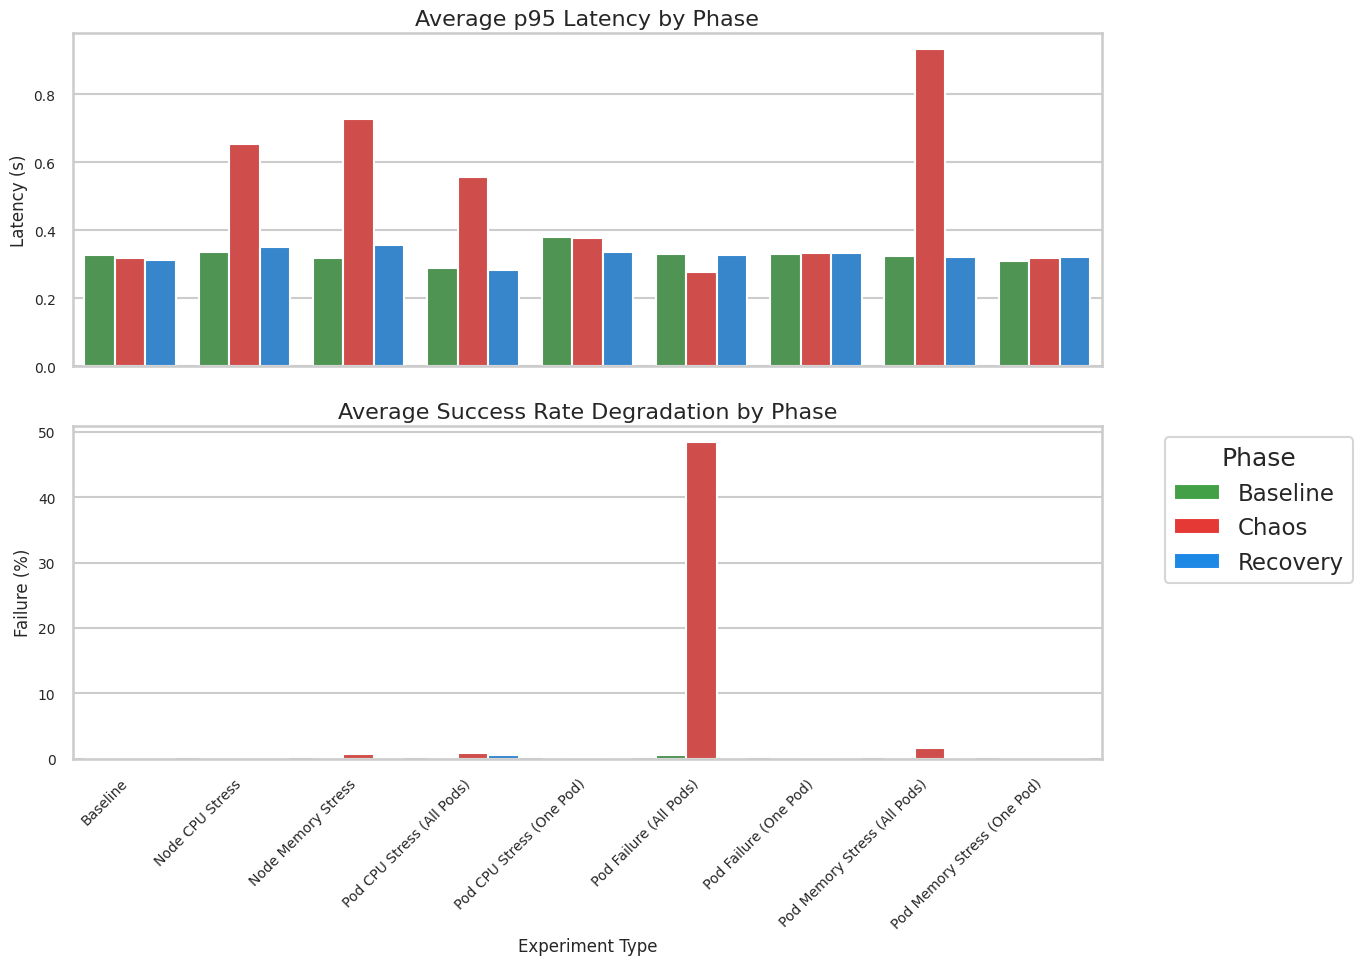

In [6]:
import matplotlib.ticker as mtick

latency_levels = (
    df.groupby('category')[['baseline_latency', 'chaos_latency', 'recovery_latency']]
      .mean()
      .reset_index()
      .melt(id_vars='category', var_name='phase', value_name='latency_seconds')
)

success_levels = (
    df.groupby('category')[['baseline_success_rate', 'chaos_success_rate', 'recovery_success_rate']]
      .mean()
      .reset_index()
      .melt(id_vars='category', var_name='phase', value_name='success_rate')
)


# Create a "failure rate" column for visualization
failure_levels = success_levels.copy()
failure_levels['failure_rate'] = 100 - failure_levels['success_rate']

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# --- Latency plot ---
sns.barplot(
    data=latency_levels,
    x='category', y='latency_seconds', hue='phase',
    hue_order=['baseline_latency', 'chaos_latency', 'recovery_latency'],
    palette=['#43a047', '#e53935', '#1e88e5'],
    ax=axes[0],
    dodge=True
)
axes[0].set_title('Average p95 Latency by Phase')
axes[0].set_ylabel('Latency (s)')
axes[0].legend_.remove()  # remove legend

# --- Success degradation plot (log scale) ---
sns.barplot(
    data=failure_levels,
    x='category', y='failure_rate', hue='phase',
    hue_order=['baseline_success_rate', 'chaos_success_rate', 'recovery_success_rate'],
    palette=['#43a047', '#e53935', '#1e88e5'],
    ax=axes[1],
    dodge=True
)
axes[1].set_title('Average Success Rate Degradation by Phase')
axes[1].set_ylabel('Failure (%)')
axes[1].set_xlabel('Experiment Type')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].legend_.remove()  # remove legend

# --- Single shared legend ---
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#43a047', label='Baseline'),
    Patch(facecolor='#e53935', label='Chaos'),
    Patch(facecolor='#1e88e5', label='Recovery')
]
axes[1].legend(handles=legend_elements, title='Phase', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


## 5. Recovery vs. Location Identification

Compare how often the system recovered (latency ≤ 20% & success rate ≤ 1%) with how often the agent identified the correct problem location.

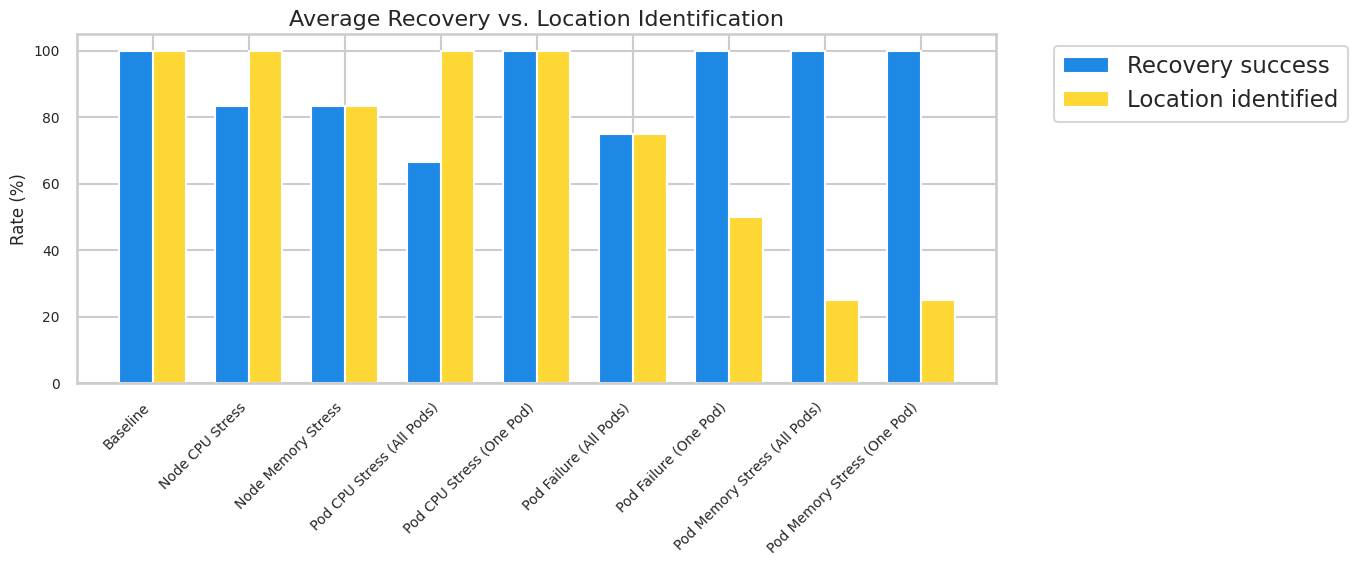

In [7]:
recovery_vs_location = (
    df.groupby('category')[['recovery_success', 'location_identified']]
      .mean()
      .rename(columns={'recovery_success': 'Recovery success', 'location_identified': 'Location identified'})
      .reset_index()
)

fig, ax = plt.subplots(figsize=(14, 6))
width = 0.35
positions = np.arange(len(recovery_vs_location))

ax.bar(positions - width/2, recovery_vs_location['Recovery success'] * 100, width, label='Recovery success', color='#1e88e5')
ax.bar(positions + width/2, recovery_vs_location['Location identified'] * 100, width, label='Location identified', color='#fdd835')

ax.set_xticks(positions)
ax.set_xticklabels(recovery_vs_location['category'], rotation=45, ha='right')
ax.set_ylabel('Rate (%)')
ax.set_title('Average Recovery vs. Location Identification')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 6. Within-20%-of-Baseline Agreement

Contrast the `within_20pct_baseline` flag stored in the logs with the value rederived from the baseline/chaos/recovery metrics.

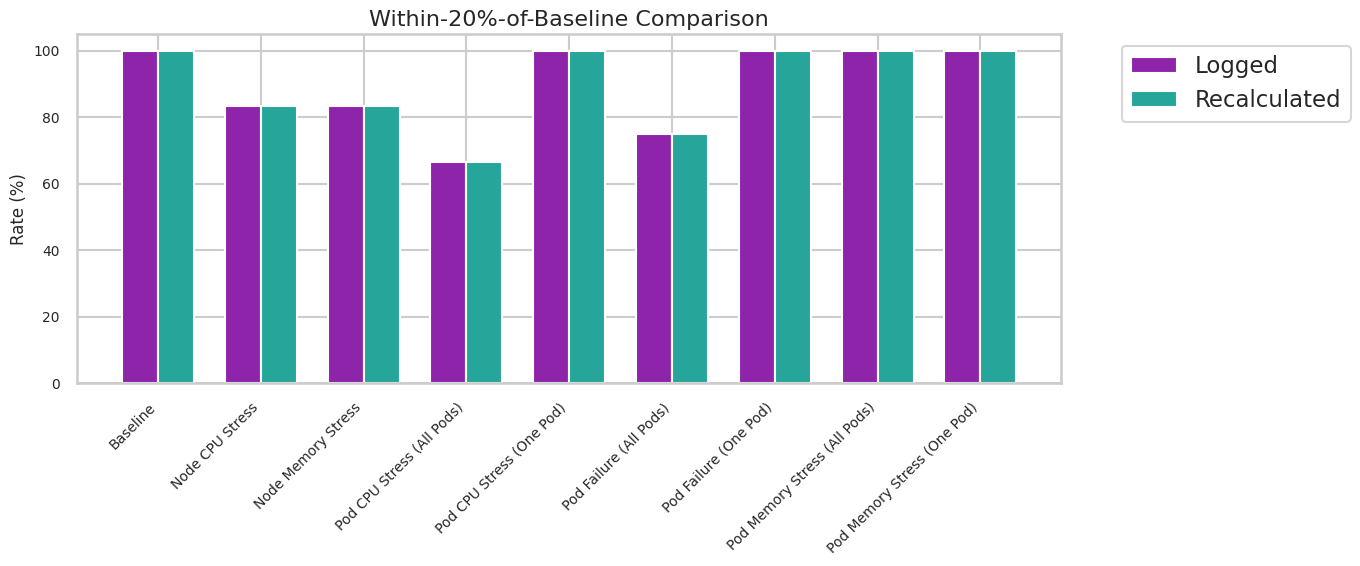

Experiments where logged and recalculated values differ: 0


In [8]:
within20_summary = (
    df.groupby('category')[['within20_logged', 'within20_recalc']]
      .mean()
      .rename(columns={'within20_logged': 'Logged within 20%', 'within20_recalc': 'Recalculated within 20%'})
      .reset_index()
)

fig, ax = plt.subplots(figsize=(14, 6))
width = 0.35
positions = np.arange(len(within20_summary))

ax.bar(positions - width/2, within20_summary['Logged within 20%'] * 100, width, label='Logged', color='#8e24aa')
ax.bar(positions + width/2, within20_summary['Recalculated within 20%'] * 100, width, label='Recalculated', color='#26a69a')

ax.set_xticks(positions)
ax.set_xticklabels(within20_summary['category'], rotation=45, ha='right')
ax.set_ylabel('Rate (%)')
ax.set_title('Within-20%-of-Baseline Comparison')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

print(f"Experiments where logged and recalculated values differ: {(df['within20_logged'] != df['within20_recalc']).sum()}")

## 7. Agent Effort: Execution Time and Rounds

Average agent runtime and number of steps per experiment type.

/tmp/ipykernel_1805213/1498999186.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = df.groupby('category').agg({


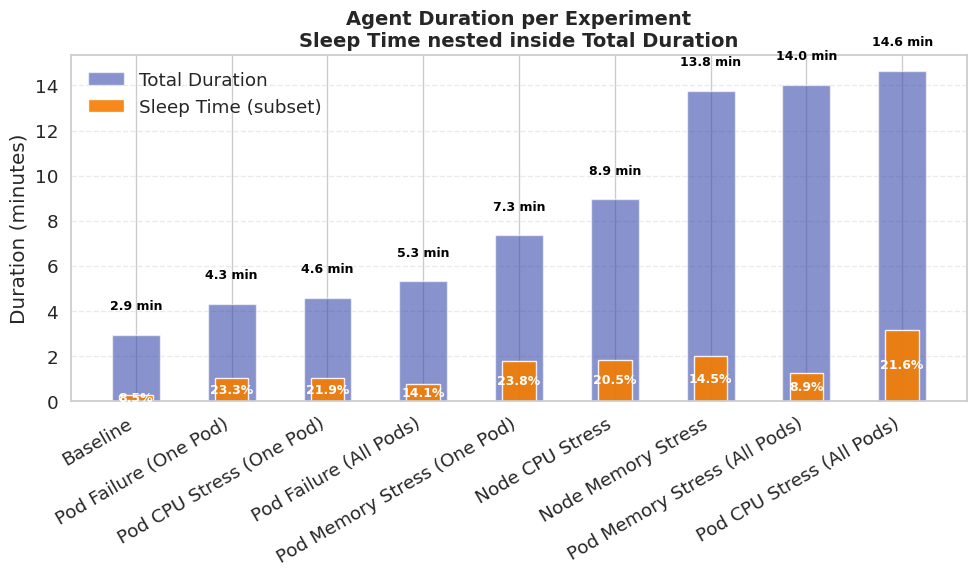

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Compute metrics ---
df['agent_active_minutes'] = (df['agent_duration_minutes'] - df['agent_sleep_minutes']).clip(lower=0)

# Sort categories for consistency
categories_order = df.groupby('category')['agent_duration_minutes'].mean().sort_values().index
df['category'] = pd.Categorical(df['category'], categories=categories_order, ordered=True)

# --- Prepare summary for plotting ---
summary = df.groupby('category').agg({
    'agent_duration_minutes': 'mean',
    'agent_sleep_minutes': 'mean',
    'agent_active_minutes': 'mean'
}).reset_index()

summary['sleep_pct'] = (summary['agent_sleep_minutes'] / summary['agent_duration_minutes'] * 100).round(1)
summary['active_pct'] = 100 - summary['sleep_pct']

# --- Plot setup ---
sns.set_theme(style="whitegrid", font_scale=1.2)
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(summary))
width = 0.5

# Total duration bars (blue)
ax.bar(x, summary['agent_duration_minutes'], color='#3949ab', alpha=0.6, width=width, label='Total Duration')

# Sleep time overlay (orange)
ax.bar(x, summary['agent_sleep_minutes'], color='#f57c00', alpha=0.9, width=width*0.7, label='Sleep Time (subset)')

# Annotate values
for i, row in summary.iterrows():
    ax.text(i, row['agent_duration_minutes'] + 1, f"{row['agent_duration_minutes']:.1f} min",
            ha='center', va='bottom', fontsize=9, fontweight='bold', color='black')
    ax.text(i, row['agent_sleep_minutes']/2, f"{row['sleep_pct']}%", 
            ha='center', va='center', fontsize=9, fontweight='bold', color='white')

# Styling
ax.set_xticks(x)
ax.set_xticklabels(summary['category'], rotation=30, ha='right')
ax.set_ylabel("Duration (minutes)")
ax.set_title("Agent Duration per Experiment\nSleep Time nested inside Total Duration", fontsize=14, fontweight='bold')
ax.legend(frameon=False, loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


/tmp/ipykernel_1805213/972355965.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1805213/972355965.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means_steps = df.groupby('category')['agent_steps'].mean().reindex(categories_order)


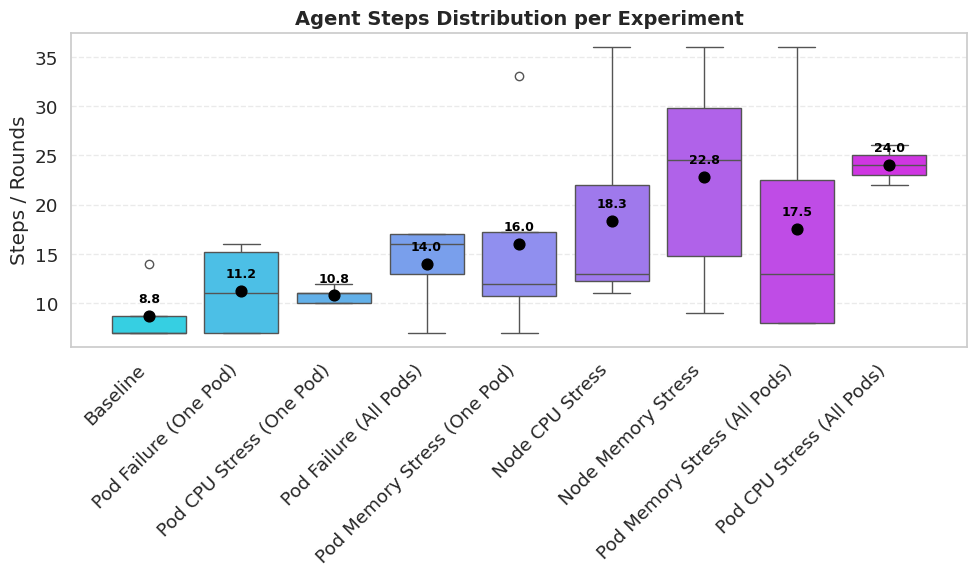

In [10]:
# --- Fixed Steps distribution plot ---
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Ensure categories_order exists (from previous code)
# categories_order = df.groupby('category')['agent_duration_minutes'].mean().sort_values().index

# Make sure 'category' is categorical with the same order
df['category'] = pd.Categorical(df['category'], categories=categories_order, ordered=True)

sns.set_theme(style="whitegrid", font_scale=1.2)
fig, ax = plt.subplots(figsize=(10, 6))

# create a palette with correct number of colors
palette = sns.color_palette("cool", n_colors=len(categories_order))

# Pass explicit order to boxplot so ticks align with data
sns.boxplot(
    data=df,
    x='category',
    y='agent_steps',
    order=categories_order,
    palette=palette,
    showmeans=False,        # we'll plot means manually for better control
    ax=ax
)

# Compute means in the same order and plot them
means_steps = df.groupby('category')['agent_steps'].mean().reindex(categories_order)
x_positions = np.arange(len(categories_order))

# Plot mean markers and annotate
for i, (cat, mean_val) in enumerate(means_steps.items()):
    ax.scatter(i, mean_val, color='black', s=60, zorder=3)
    ax.text(i, mean_val + (df['agent_steps'].max() * 0.03), f"{mean_val:.1f}",
            ha='center', va='bottom', fontsize=9, fontweight='bold', color='black', clip_on=False)

# Ticks and labels
ax.set_xticks(x_positions)
ax.set_xticklabels([str(c) for c in categories_order], rotation=45, ha='right')
ax.set_title("Agent Steps Distribution per Experiment", fontsize=14, fontweight='bold')
ax.set_xlabel("")
ax.set_ylabel("Steps / Rounds")
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


## 8. Threshold Compliance per Experiment

Each point shows whether an experiment satisfied the latency ≤ 20% and success rate ≤ 1% thresholds.

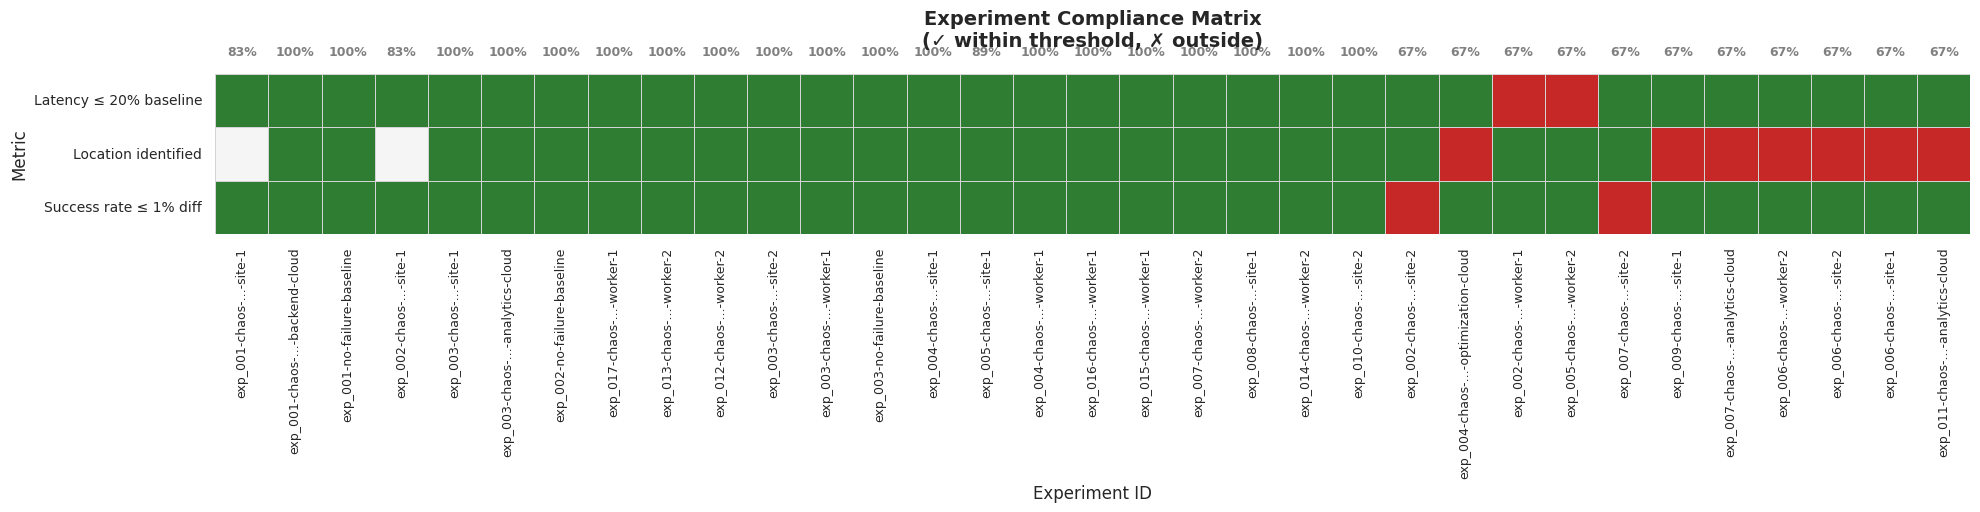

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Prepare long-format compliance data ---
compliance_long = (
    df[['experiment_id', 'category', 'latency_within_20pct', 'success_within_1pct', 'location_identified']]
      .melt(id_vars=['experiment_id', 'category'], var_name='metric', value_name='within_threshold')
)

# Map readable labels
label_map = {
    'latency_within_20pct': 'Latency ≤ 20% baseline',
    'success_within_1pct': 'Success rate ≤ 1% diff',
    'location_identified': 'Location identified'
}
compliance_long['metric'] = compliance_long['metric'].map(label_map)

# Shorten experiment IDs for plotting
def shorten_experiment_id(exp_id):
    if pd.isna(exp_id): 
        return exp_id
    parts = exp_id.split('-')
    if len(parts) > 4:
        return '-'.join(parts[:2] + ['...'] + parts[-2:])
    return exp_id

compliance_long['exp_id_short'] = compliance_long['experiment_id'].apply(shorten_experiment_id)

# Pivot for heatmap: metrics x experiments
pivot_df = compliance_long.pivot_table(
    index='metric', columns='exp_id_short', values='within_threshold'
)

# Sort experiments by category mean compliance
mean_compliance = compliance_long.groupby('experiment_id')['within_threshold'].mean()
exp_order = mean_compliance.sort_values(ascending=False).index
pivot_df = pivot_df[compliance_long.set_index('experiment_id').loc[exp_order]['exp_id_short'].unique()]

# --- Create the heatmap ---
plt.figure(figsize=(20, 6))
sns.set_theme(style="whitegrid", font_scale=1.1)

# Convert True/False/NaN → numeric
heat_data = pivot_df.replace({True: 1, False: 0})

# Define color palette: green=1, red=0, gray=NaN
cmap = sns.color_palette(["#c62828", "#f5f5f5", "#2e7d32"])
sns.heatmap(
    heat_data,
    cmap=["#c62828", "#f5f5f5", "#2e7d32"],
    cbar=False,
    linewidths=0.5,
    linecolor='lightgray',
    square=True
)

# --- Annotate experiment-level compliance (mean %) above each column ---
col_means = heat_data.mean().round(2)
for i, (exp, val) in enumerate(col_means.items()):
    plt.text(i + 0.5, -0.3, f"{int(val * 100)}%", ha='center', va='bottom', fontsize=9, color='gray', fontweight='bold')

plt.title("Experiment Compliance Matrix\n(✓ within threshold, ✗ outside)", fontsize=14, fontweight='bold', pad=20)
plt.xlabel("Experiment ID", fontsize=12)
plt.ylabel("Metric", fontsize=12)

plt.xticks(rotation=90, ha='center', fontsize=9)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()


## 9. Filtered Analysis: Experiments with Actual Degradation

Some experiments had chaos active but no actual degradation in latency or success rate. In these cases, the agent correctly left the problem location blank ([]). This section filters to only experiments with actual degradation for more meaningful location identification analysis.


In [12]:
# Identify experiments with actual degradation
# An experiment has degradation if either latency or success rate degraded during chaos
has_latency_degradation = df['latency_degradation_pct'] > 1.0  # More than 1% latency increase
has_success_degradation = df['success_degradation_pct'] > 1.0  # More than 1% success rate decrease
has_any_degradation = has_latency_degradation | has_success_degradation

# Filter to only experiments with actual degradation
df_filtered = df[has_any_degradation].copy()

print(f"Total experiments: {len(df)}")
print(f"Experiments with actual degradation: {len(df_filtered)}")
print(f"Experiments excluded (no degradation): {len(df) - len(df_filtered)}")
print(f"\nExcluded experiments:")
excluded = df[~has_any_degradation][['experiment_id', 'category', 'latency_degradation_pct', 'success_degradation_pct', 'location_identified']]
print(excluded.to_string(index=False))

print(f"\n{'='*80}")
print("FILTERED DATASET STATISTICS")
print(f"{'='*80}")

# Location identification rate on filtered dataset
location_rate_filtered = df_filtered['location_identified'].mean() * 100
print(f"\nLocation Identification Rate (filtered): {location_rate_filtered:.1f}%")
print(f"Location Identification Rate (all experiments): {df['location_identified'].mean() * 100:.1f}%")

# Recovery success rate on filtered dataset
recovery_rate_filtered = df_filtered['recovery_success'].mean() * 100
print(f"\nRecovery Success Rate (filtered): {recovery_rate_filtered:.1f}%")
print(f"Recovery Success Rate (all experiments): {df['recovery_success'].mean() * 100:.1f}%")


Total experiments: 40
Experiments with actual degradation: 31
Experiments excluded (no degradation): 9

Excluded experiments:
                                                     experiment_id                     category  latency_degradation_pct  success_degradation_pct  location_identified
                                       exp_002-no-failure-baseline                     Baseline                 0.900901                     0.00                 True
                                       exp_002-no-failure-baseline                     Baseline               -11.581292                     0.00                 True
                                       exp_001-no-failure-baseline                     Baseline                -6.880734                     0.00                 True
        exp_001-chaos-cpu-stress-traffic-sensor-ingest-edge-site-1     Pod CPU Stress (One Pod)               -20.777027                     0.75                 True
       exp_002-chaos-cpu-stress-edge-tr

/tmp/ipykernel_1805213/482932073.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_filtered.groupby('category')[['recovery_success', 'location_identified']]


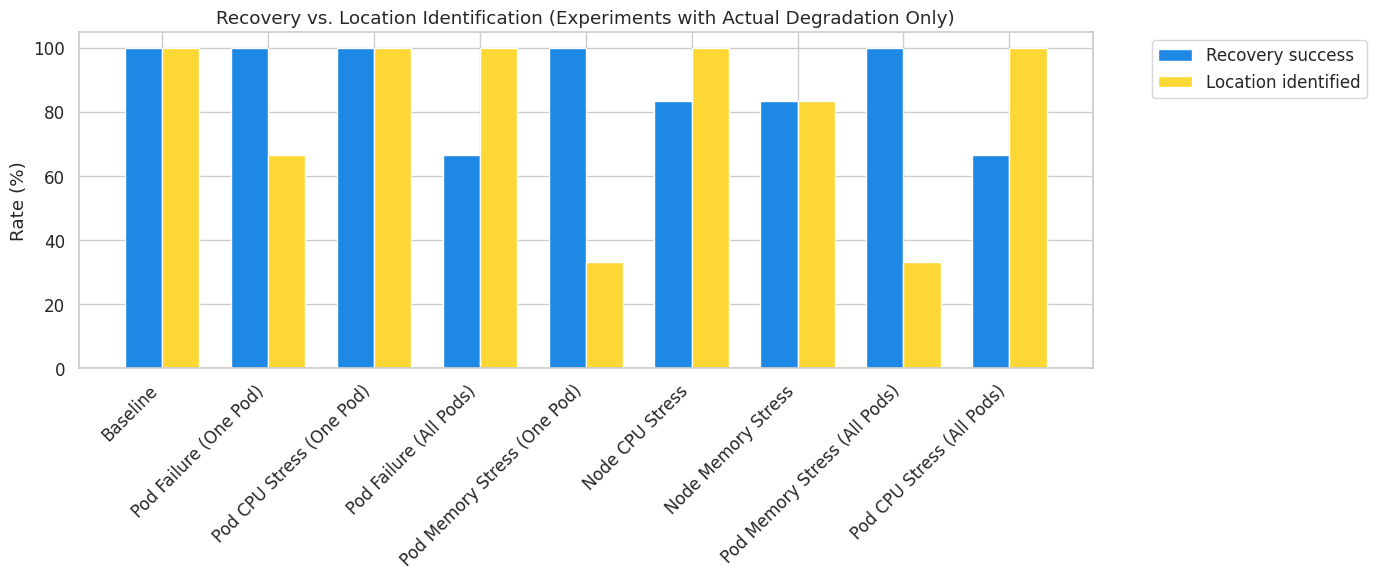

In [13]:
# Recovery vs Location Identification on filtered dataset
recovery_vs_location_filtered = (
    df_filtered.groupby('category')[['recovery_success', 'location_identified']]
      .mean()
      .rename(columns={'recovery_success': 'Recovery success', 'location_identified': 'Location identified'})
      .reset_index()
)

fig, ax = plt.subplots(figsize=(14, 6))
width = 0.35
positions = np.arange(len(recovery_vs_location_filtered))

ax.bar(positions - width/2, recovery_vs_location_filtered['Recovery success'] * 100, width, label='Recovery success', color='#1e88e5')
ax.bar(positions + width/2, recovery_vs_location_filtered['Location identified'] * 100, width, label='Location identified', color='#fdd835')

ax.set_xticks(positions)
ax.set_xticklabels(recovery_vs_location_filtered['category'], rotation=45, ha='right')
ax.set_ylabel('Rate (%)')
ax.set_title('Recovery vs. Location Identification (Experiments with Actual Degradation Only)')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 9. Aggregate Metrics Across All Experiments

Overall averages for degradation, recovery, and success-related metrics across the entire dataset.

In [14]:
# Calculate comprehensive aggregate metrics
duration_mean = df['agent_duration_minutes'].mean()
duration_std = df['agent_duration_minutes'].std()
duration_min = df['agent_duration_minutes'].min()
duration_max = df['agent_duration_minutes'].max()

sleep_mean = df['agent_sleep_minutes'].mean()
sleep_std = df['agent_sleep_minutes'].std()
sleep_min = df['agent_sleep_minutes'].min()
sleep_max = df['agent_sleep_minutes'].max()

active_mean = df['agent_active_minutes'].mean()
active_std = df['agent_active_minutes'].std()

rounds_mean = df['agent_steps'].mean()
rounds_std = df['agent_steps'].std()
rounds_min = df['agent_steps'].min()
rounds_max = df['agent_steps'].max()

# Calculate average number of unique actions per experiment
def count_unique_actions(filepath):
    try:
        if filepath and filepath.exists():
            with open(filepath) as f:
                data = json.load(f)
            agent_trace = data.get('agent_trace', [])
            actions = [step.get('action') for step in agent_trace if step.get('action')]
            return len(set(actions)) if actions else 0
    except:
        pass
    return 0

# Add unique actions count to dataframe if not already present
if 'unique_actions' not in df.columns:
    # Create a mapping from filename to full path using available_files from cell 3
    file_map = {fp.name: fp for fp in available_files}
    df['unique_actions'] = df['file'].apply(lambda f: count_unique_actions(file_map.get(f)))

actions_mean = df['unique_actions'].mean()
actions_std = df['unique_actions'].std()
actions_min = df['unique_actions'].min()
actions_max = df['unique_actions'].max()

# Build comprehensive metrics table
overall_metrics = {
    'Metric': [
        'Latency Degradation During Chaos (%)',
        'Success-Rate Degradation During Chaos (%)',
        'Latency Recovery Index (%)',
        'Success-Rate Recovery Index (%)',
        'Composite Recovery Index (%)',
        'Experiments Meeting Both Thresholds (%)',
        'Experiments with Location Identified (%)',
        'Average Agent Duration (minutes)',
        'Agent Duration Range (min-max)',
        'Agent Duration Std Dev (±)',
        'Average Sleep Time (minutes)',
        'Sleep Time Range (min-max)',
        'Sleep Time Std Dev (±)',
        'Sleep Time as % of Duration',
        'Average Active Time (minutes)',
        'Active Time Std Dev (±)',
        'Average Agent Rounds',
        'Agent Rounds Range (min-max)',
        'Agent Rounds Std Dev (±)',
        'Average Unique Actions per Experiment',
        'Unique Actions Range (min-max)',
        'Unique Actions Std Dev (±)',
    ],
    'Value': [
        f"{df['latency_degradation_pct'].mean():.2f}",
        f"{df['success_degradation_pct'].mean():.2f}",
        f"{df['latency_recovery_pct'].mean():.2f}",
        f"{df['success_recovery_pct'].mean():.2f}",
        f"{df['recovery_index_composite'].mean():.2f}",
        f"{df['recovery_success'].mean() * 100:.2f}",
        f"{df['location_identified'].mean() * 100:.2f}",
        f"{duration_mean:.2f}",
        f"{duration_min:.2f} - {duration_max:.2f}",
        f"±{duration_std:.2f}",
        f"{sleep_mean:.2f}",
        f"{sleep_min:.2f} - {sleep_max:.2f}",
        f"±{sleep_std:.2f}",
        f"{(sleep_mean / duration_mean * 100) if duration_mean > 0 else 0:.2f}",
        f"{active_mean:.2f}",
        f"±{active_std:.2f}",
        f"{rounds_mean:.1f}",
        f"{int(rounds_min)} - {int(rounds_max)}",
        f"±{rounds_std:.1f}",
        f"{actions_mean:.1f}",
        f"{int(actions_min)} - {int(actions_max)}",
        f"±{actions_std:.1f}",
    ]
}

overall_df = pd.DataFrame(overall_metrics)
print("\n" + "="*80)
print("COMPREHENSIVE AGGREGATE METRICS ACROSS ALL EXPERIMENTS")
print("="*80)
print(overall_df.to_string(index=False))
print("="*80)


COMPREHENSIVE AGGREGATE METRICS ACROSS ALL EXPERIMENTS
                                   Metric        Value
     Latency Degradation During Chaos (%)        59.54
Success-Rate Degradation During Chaos (%)         5.18
               Latency Recovery Index (%)        62.72
          Success-Rate Recovery Index (%)        95.14
             Composite Recovery Index (%)        78.93
  Experiments Meeting Both Thresholds (%)        90.00
 Experiments with Location Identified (%)        75.00
         Average Agent Duration (minutes)         8.47
           Agent Duration Range (min-max) 1.44 - 43.75
               Agent Duration Std Dev (±)        ±8.86
             Average Sleep Time (minutes)         1.44
               Sleep Time Range (min-max)  0.00 - 5.00
                   Sleep Time Std Dev (±)        ±1.35
              Sleep Time as % of Duration        16.98
            Average Active Time (minutes)         7.03
                  Active Time Std Dev (±)        ±7.92
         

## 10. Comparison Across App Types

Compare key metrics across different application types to identify patterns and differences in agent performance.


In [20]:
# Calculate key metrics per app type
app_comparison = df.groupby('app_type').agg({
    # Recovery metrics
    'latency_degradation_pct': ['mean', 'std'],
    'success_degradation_pct': ['mean', 'std'],
    'latency_recovery_pct': ['mean', 'std'],
    'success_recovery_pct': ['mean', 'std'],
    'recovery_index_composite': ['mean', 'std'],
    'recovery_success': 'mean',
    'location_identified': 'mean',
    # Agent effort metrics
    'agent_duration_minutes': ['mean', 'std', 'min', 'max'],
    'agent_sleep_minutes': ['mean', 'std'],
    'agent_active_minutes': ['mean', 'std'],
    'agent_steps': ['mean', 'std', 'min', 'max'],
    # Count experiments
    'experiment_id': 'count'
}).round(2)

# Flatten column names
app_comparison.columns = ['_'.join(col).strip() for col in app_comparison.columns.values]
app_comparison = app_comparison.reset_index()
app_comparison.rename(columns={'experiment_id_count': 'num_experiments'}, inplace=True)

# Create comparison table with key metrics
comparison_table = pd.DataFrame({
    'App Type': app_comparison['app_type'],
    'Num Experiments': app_comparison['num_experiments'].astype(int),
    'Recovery Success Rate (%)': (app_comparison['recovery_success_mean'] * 100).round(1),
    'Location Identified Rate (%)': (app_comparison['location_identified_mean'] * 100).round(1),
    'Avg Composite Recovery Index (%)': app_comparison['recovery_index_composite_mean'].round(1),
    'Avg Latency Recovery (%)': app_comparison['latency_recovery_pct_mean'].round(1),
    'Avg Success Rate Recovery (%)': app_comparison['success_recovery_pct_mean'].round(1),
    'Avg Duration (min)': app_comparison['agent_duration_minutes_mean'].round(2),
    'Duration Range (min-max)': (
        app_comparison['agent_duration_minutes_min'].round(1).astype(str) + ' - ' +
        app_comparison['agent_duration_minutes_max'].round(1).astype(str)
    ),
    'Avg Sleep Time (min)': app_comparison['agent_sleep_minutes_mean'].round(2),
    'Sleep % of Duration': (
        (app_comparison['agent_sleep_minutes_mean'] / 
         app_comparison['agent_duration_minutes_mean'] * 100).round(1).astype(str) + '%'
    ),
    'Avg Rounds': app_comparison['agent_steps_mean'].round(1),
    'Rounds Range (min-max)': (
        app_comparison['agent_steps_min'].astype(int).astype(str) + ' - ' +
        app_comparison['agent_steps_max'].astype(int).astype(str)
    ),
})

print("\n" + "="*100)
print("KEY METRICS COMPARISON BY APP TYPE")
print("="*100)
print(comparison_table.to_string(index=False))
print("="*100)


KEY METRICS COMPARISON BY APP TYPE
               App Type  Num Experiments  Recovery Success Rate (%)  Location Identified Rate (%)  Avg Composite Recovery Index (%)  Avg Latency Recovery (%)  Avg Success Rate Recovery (%)  Avg Duration (min) Duration Range (min-max)  Avg Sleep Time (min) Sleep % of Duration  Avg Rounds Rounds Range (min-max)
         app-smart-city               20                       85.0                          75.0                              81.9                      63.4                          100.3               10.70               1.7 - 43.8                  1.72               16.1%        17.4                 7 - 36
app-smart-manufacturing               20                       95.0                          75.0                              76.0                      62.0                           90.0                6.23               1.4 - 18.2                  1.15               18.5%        14.8                 7 - 33


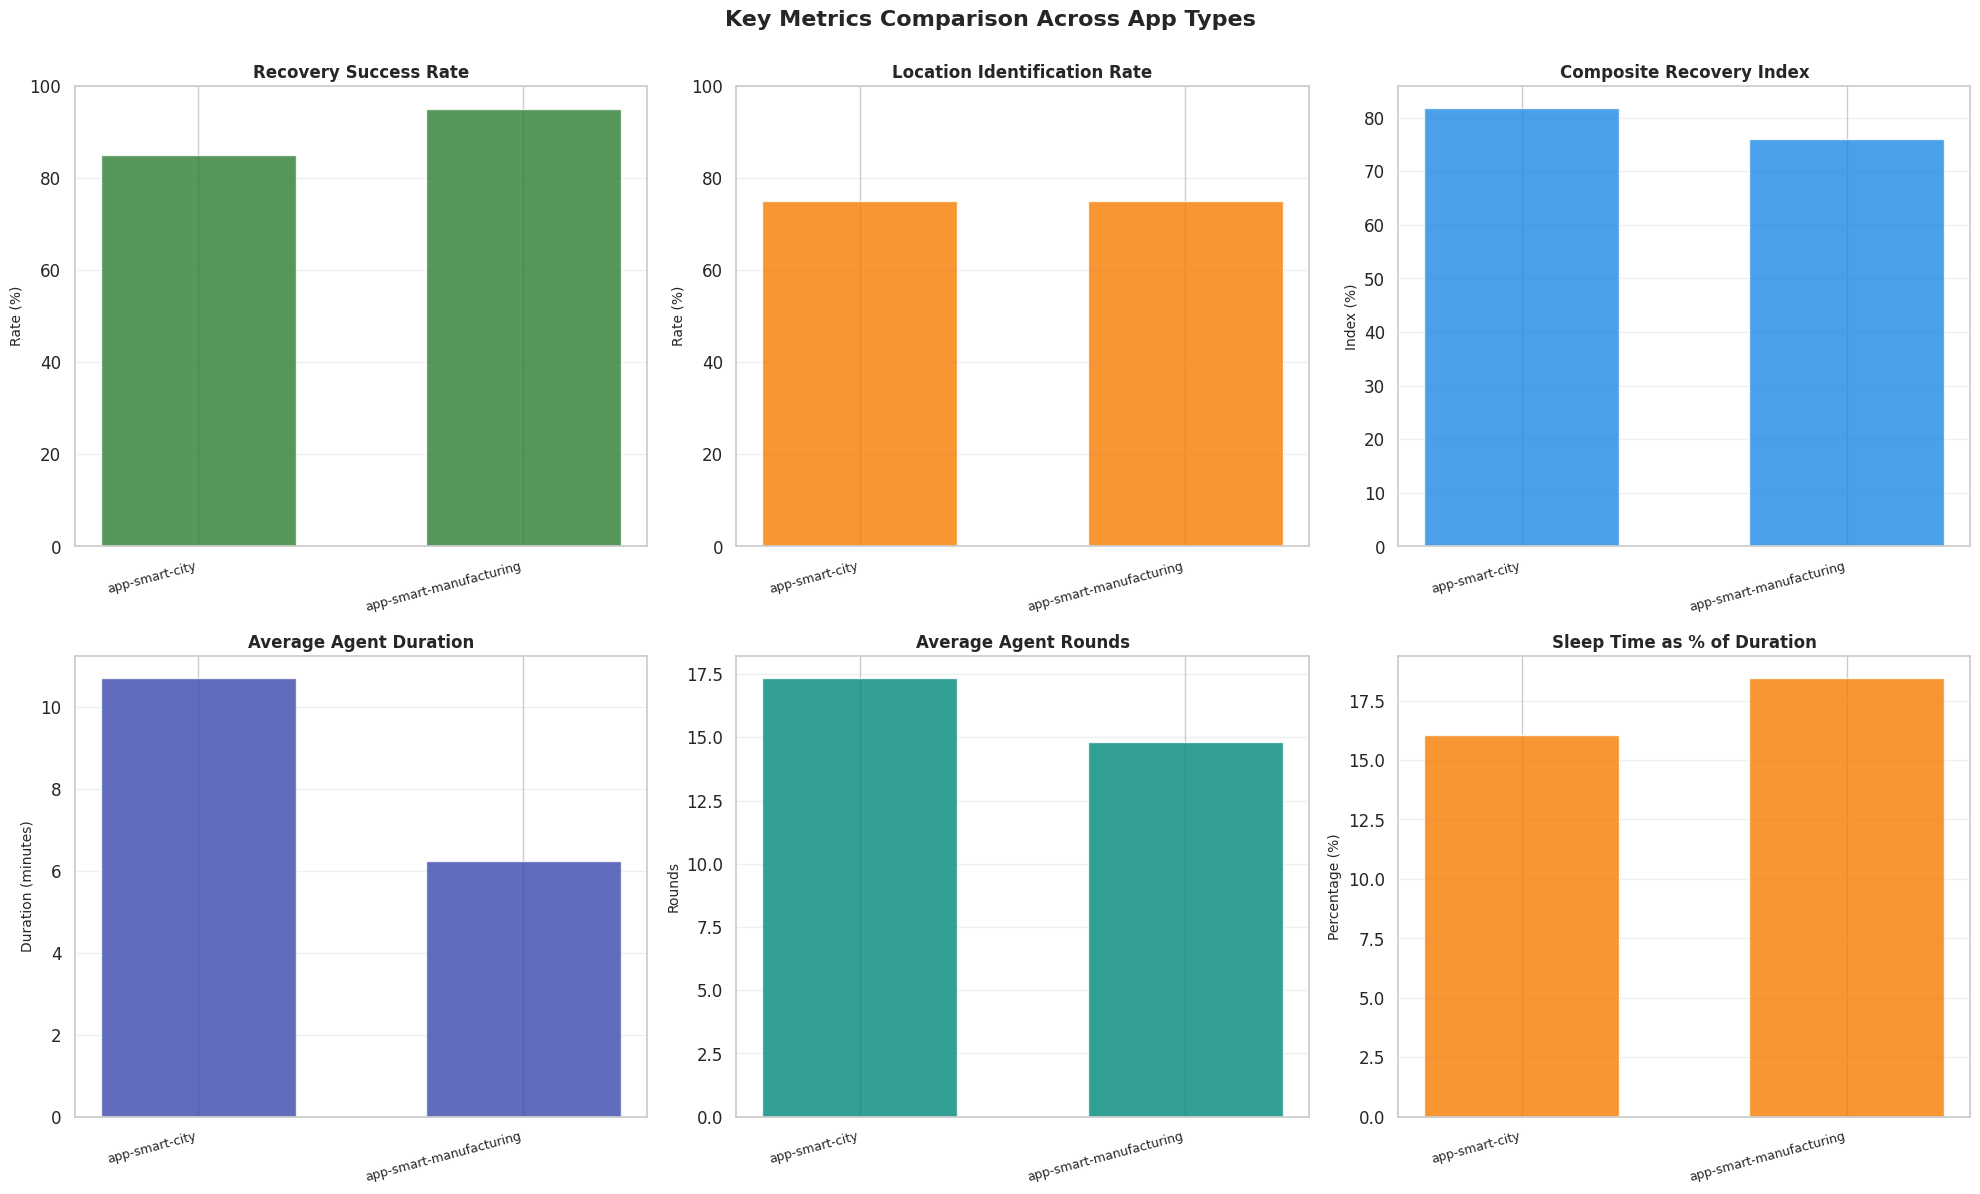

In [21]:
# Create comparison visualizations
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

app_types = app_comparison['app_type'].values
x_pos = np.arange(len(app_types))
width = 0.6

# 1. Recovery Success Rate
axes[0, 0].bar(x_pos, app_comparison['recovery_success_mean'] * 100, width, 
               color='#2e7d32', alpha=0.8)
axes[0, 0].set_title('Recovery Success Rate', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Rate (%)', fontsize=10)
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(app_types, rotation=15, ha='right', fontsize=9)
axes[0, 0].grid(axis='y', alpha=0.3)
axes[0, 0].set_ylim([0, 100])

# 2. Location Identification Rate
axes[0, 1].bar(x_pos, app_comparison['location_identified_mean'] * 100, width,
               color='#f57c00', alpha=0.8)
axes[0, 1].set_title('Location Identification Rate', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Rate (%)', fontsize=10)
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(app_types, rotation=15, ha='right', fontsize=9)
axes[0, 1].grid(axis='y', alpha=0.3)
axes[0, 1].set_ylim([0, 100])

# 3. Composite Recovery Index
axes[0, 2].bar(x_pos, app_comparison['recovery_index_composite_mean'], width,
               color='#1e88e5', alpha=0.8)
axes[0, 2].set_title('Composite Recovery Index', fontsize=12, fontweight='bold')
axes[0, 2].set_ylabel('Index (%)', fontsize=10)
axes[0, 2].set_xticks(x_pos)
axes[0, 2].set_xticklabels(app_types, rotation=15, ha='right', fontsize=9)
axes[0, 2].grid(axis='y', alpha=0.3)

# 4. Average Duration
axes[1, 0].bar(x_pos, app_comparison['agent_duration_minutes_mean'], width,
               color='#3949ab', alpha=0.8)
axes[1, 0].set_title('Average Agent Duration', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Duration (minutes)', fontsize=10)
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(app_types, rotation=15, ha='right', fontsize=9)
axes[1, 0].grid(axis='y', alpha=0.3)

# 5. Average Rounds
axes[1, 1].bar(x_pos, app_comparison['agent_steps_mean'], width,
               color='#00897b', alpha=0.8)
axes[1, 1].set_title('Average Agent Rounds', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Rounds', fontsize=10)
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(app_types, rotation=15, ha='right', fontsize=9)
axes[1, 1].grid(axis='y', alpha=0.3)

# 6. Sleep Time as % of Duration
sleep_pct = (app_comparison['agent_sleep_minutes_mean'] / 
             app_comparison['agent_duration_minutes_mean'] * 100)
axes[1, 2].bar(x_pos, sleep_pct, width,
               color='#f57c00', alpha=0.8)
axes[1, 2].set_title('Sleep Time as % of Duration', fontsize=12, fontweight='bold')
axes[1, 2].set_ylabel('Percentage (%)', fontsize=10)
axes[1, 2].set_xticks(x_pos)
axes[1, 2].set_xticklabels(app_types, rotation=15, ha='right', fontsize=9)
axes[1, 2].grid(axis='y', alpha=0.3)

plt.suptitle('Key Metrics Comparison Across App Types', fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

In [22]:
# Detailed comparison table with degradation metrics
detailed_comparison = pd.DataFrame({
    'App Type': app_comparison['app_type'],
    'Num Experiments': app_comparison['num_experiments'].astype(int),
    'Avg Latency Degradation (%)': app_comparison['latency_degradation_pct_mean'].round(1),
    'Avg Success Rate Degradation (%)': app_comparison['success_degradation_pct_mean'].round(1),
    'Avg Latency Recovery (%)': app_comparison['latency_recovery_pct_mean'].round(1),
    'Avg Success Rate Recovery (%)': app_comparison['success_recovery_pct_mean'].round(1),
    'Composite Recovery Index (%)': app_comparison['recovery_index_composite_mean'].round(1),
    'Recovery Success Rate (%)': (app_comparison['recovery_success_mean'] * 100).round(1),
    'Location Identified Rate (%)': (app_comparison['location_identified_mean'] * 100).round(1),
    'Avg Duration (min)': app_comparison['agent_duration_minutes_mean'].round(2),
    'Duration Std Dev (±)': app_comparison['agent_duration_minutes_std'].round(2),
    'Avg Sleep (min)': app_comparison['agent_sleep_minutes_mean'].round(2),
    'Avg Active (min)': app_comparison['agent_active_minutes_mean'].round(2),
    'Avg Rounds': app_comparison['agent_steps_mean'].round(1),
    'Rounds Std Dev (±)': app_comparison['agent_steps_std'].round(1),
})

print("\n" + "="*120)
print("DETAILED METRICS COMPARISON BY APP TYPE")
print("="*120)
print(detailed_comparison.to_string(index=False))
print("="*120)


DETAILED METRICS COMPARISON BY APP TYPE
               App Type  Num Experiments  Avg Latency Degradation (%)  Avg Success Rate Degradation (%)  Avg Latency Recovery (%)  Avg Success Rate Recovery (%)  Composite Recovery Index (%)  Recovery Success Rate (%)  Location Identified Rate (%)  Avg Duration (min)  Duration Std Dev (±)  Avg Sleep (min)  Avg Active (min)  Avg Rounds  Rounds Std Dev (±)
         app-smart-city               20                         51.9                               7.7                      63.4                          100.3                          81.9                       85.0                          75.0               10.70                 11.11             1.72              8.98        17.4                 9.7
app-smart-manufacturing               20                         67.2                               2.7                      62.0                           90.0                          76.0                       95.0                          75

## 10. Export Processed Dataset

Save the processed per-experiment dataset for downstream analysis.

In [18]:
# output_path = Path('processed_experiments.csv')
# df.to_csv(output_path, index=False)
# print(f'Saved processed dataset to {output_path.resolve()}')

### Key Takeaways

- **Degradation vs. recovery:** The summary table quantifies average chaos degradation relative to baseline and how much of that degradation the system regained.
- **Recovery vs. detection:** Comparing recovery success with location identification rates indicates whether the agent not only recovers the system but also diagnoses the fault.
- **Agent effort:** Runtime and step counts highlight which experiment types require the most effort from the agent.
- **Threshold compliance:** The scatter plot shows any experiments falling outside the latency or success-rate thresholds, while the within-20% comparison validates log integrity.
- **Global view:** The final bar chart aggregates the most important metrics across the entire dataset for a quick health check.